## Problema 4 — Classificação de Risco de Crédito com Árvore de Decisão

### 1. Carregamento e Exploração dos Dados

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

dataset = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = dataset.frame.copy()

display(df.head())

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


### 1.1. Análise exploratória

In [2]:
print("Dimensões:", df.shape)

print("\nInformações gerais:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe(include="all"))

print("\nRegistros duplicados:", df.duplicated().sum())

Dimensões: (1000, 21)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   categor

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000,...,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000
unique,4,NaN,5,10,NaN,5,5,NaN,4,3,...,4,NaN,3,3,NaN,4,NaN,2,2,2
top,no checking,NaN,existing paid,radio/tv,NaN,<100,1<=X<4,NaN,male single,none,...,car,NaN,none,own,NaN,skilled,NaN,none,yes,good
freq,394,NaN,530,280,NaN,603,339,NaN,548,907,...,332,NaN,814,713,NaN,630,NaN,596,963,700
mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,NaN,...,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,NaN
std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,NaN,...,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,NaN
min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,NaN,...,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,NaN,...,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,NaN,...,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN
75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,NaN,...,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,NaN



Registros duplicados: 0


In [3]:
X = df.drop(columns=["class"])
y = df["class"]

variaveis_numericas = X.select_dtypes(
    include="number"
).columns.tolist()

variaveis_categoricas = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Variáveis numéricas:")
print(variaveis_numericas)

print("\nVariáveis categóricas:")
print(variaveis_categoricas)

print("\nQuantidade de variáveis numéricas:",
      len(variaveis_numericas))

print("Quantidade de variáveis categóricas:",
      len(variaveis_categoricas))

Variáveis numéricas:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Variáveis categóricas:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Quantidade de variáveis numéricas: 7
Quantidade de variáveis categóricas: 13


## 2. Preparação dos Dados

### 2.1. Codificação da variável alvo

In [4]:
print("Classes originais:")
print(y.value_counts())

# Converte os rótulos
y = y.astype(str).map({
    "good": 0,
    "bad": 1
}).astype(int)

# Verifica a distribuição binária
print("\nClasses após codificação:")
print(y.value_counts().sort_index())

# Calcula os percentuais
distribuicao = pd.DataFrame({
    "Quantidade": y.value_counts().sort_index(),
    "Percentual (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    )
})

distribuicao.index = ["Bom Risco", "Mau Risco"]

display(distribuicao.round(2))

Classes originais:
class
good    700
bad     300
Name: count, dtype: int64

Classes após codificação:
class
0    700
1    300
Name: count, dtype: int64


,Quantidade,Percentual (%)
Bom Risco,700,70.0
Mau Risco,300,30.0


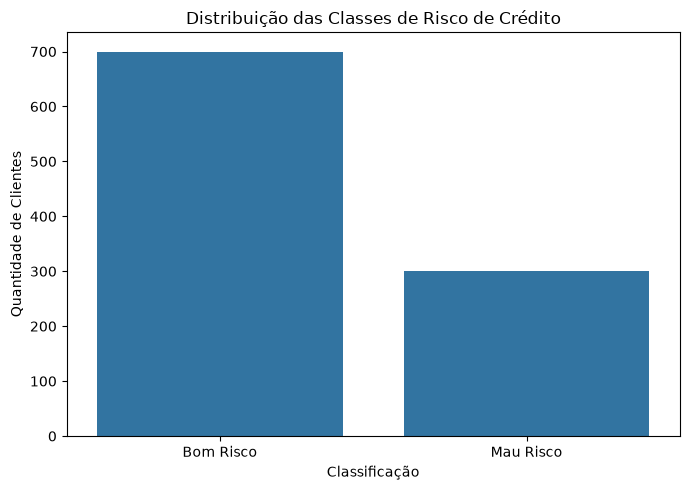

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    order=[0, 1]
)

plt.xticks(
    ticks=[0, 1],
    labels=["Bom Risco", "Mau Risco"]
)

plt.xlabel("Classificação")
plt.ylabel("Quantidade de Clientes")
plt.title("Distribuição das Classes de Risco de Crédito")

plt.tight_layout()
plt.show()

### 2.2. Divisão dos dados em treino e teste

In [6]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Amostras de treino:", X_treino.shape)
print("Amostras de teste:", X_teste.shape)

print("\nDistribuição no treino:")
print(y_treino.value_counts().sort_index())

print("\nDistribuição no teste:")
print(y_teste.value_counts().sort_index())

Amostras de treino: (800, 20)
Amostras de teste: (200, 20)

Distribuição no treino:
class
0    560
1    240
Name: count, dtype: int64

Distribuição no teste:
class
0    140
1     60
Name: count, dtype: int64


### 2.3. Codificação das variáveis categóricas

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Cria o codificador categórico
codificador = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Cria o pré-processador
preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", codificador, variaveis_categoricas),
        ("numericas", "passthrough", variaveis_numericas)
    ]
)

X_treino_proc = preprocessador.fit_transform(X_treino)

X_teste_proc = preprocessador.transform(X_teste)

print("Formato do treino:", X_treino_proc.shape)
print("Formato do teste:", X_teste_proc.shape)

Formato do treino: (800, 61)
Formato do teste: (200, 61)


### 2.4. Verificação dos dados processados

In [8]:
nomes_atributos = preprocessador.get_feature_names_out()

print("Atributos originais:", X.shape[1])
print("Atributos após codificação:", len(nomes_atributos))

print("\nTreinamento:", X_treino_proc.shape)
print("Teste:", X_teste_proc.shape)

print("\nValores ausentes no treino:",
      pd.isnull(X_treino_proc).sum())

print("Valores ausentes no teste:",
      pd.isnull(X_teste_proc).sum())

print("\nAtributos transformados:")
print(nomes_atributos)

Atributos originais: 20
Atributos após codificação: 61

Treinamento: (800, 61)
Teste: (200, 61)

Valores ausentes no treino: 0
Valores ausentes no teste: 0

Atributos transformados:
['categoricas__checking_status_0<=X<200' 'categoricas__checking_status_<0'
 'categoricas__checking_status_>=200'
 'categoricas__checking_status_no checking'
 'categoricas__credit_history_all paid'
 'categoricas__credit_history_critical/other existing credit'
 'categoricas__credit_history_delayed previously'
 'categoricas__credit_history_existing paid'
 'categoricas__credit_history_no credits/all paid'
 'categoricas__purpose_business' 'categoricas__purpose_domestic appliance'
 'categoricas__purpose_education'
 'categoricas__purpose_furniture/equipment' 'categoricas__purpose_new car'
 'categoricas__purpose_other' 'categoricas__purpose_radio/tv'
 'categoricas__purpose_repairs' 'categoricas__purpose_retraining'
 'categoricas__purpose_used car' 'categoricas__savings_status_100<=X<500'
 'categoricas__savings_stat

### 2.5. Conversão dos dados para tensores PyTorch

In [9]:
X_treino_tensor = torch.tensor(
    X_treino_proc,
    dtype=torch.float32
)

X_teste_tensor = torch.tensor(
    X_teste_proc,
    dtype=torch.float32
)

y_treino_tensor = torch.tensor(
    y_treino.to_numpy(),
    dtype=torch.long
)

y_teste_tensor = torch.tensor(
    y_teste.to_numpy(),
    dtype=torch.long
)

print("X treino:", X_treino_tensor.shape)
print("X teste:", X_teste_tensor.shape)

print("y treino:", y_treino_tensor.shape)
print("y teste:", y_teste_tensor.shape)

X treino: torch.Size([800, 61])
X teste: torch.Size([200, 61])
y treino: torch.Size([800])
y teste: torch.Size([200])


## 3. Implementação da Árvore de Decisão com PyTorch

### 3.1. Cálculo da impureza — Gini e Entropia

In [10]:
def calcular_impureza(contagens, criterio="gini"):

    # Converte para ponto flutuante
    contagens = contagens.to(torch.float64)

    # Calcula o total de amostras
    totais = contagens.sum(
        dim=-1,
        keepdim=True
    ).clamp_min(1.0)

    # Calcula a proporção de cada classe
    probabilidades = contagens / totais

    if criterio == "gini":
        return 1 - (probabilidades ** 2).sum(dim=-1)

    elif criterio == "entropy":
        return -(
            probabilidades *
            torch.log2(probabilidades.clamp_min(1e-12))
        ).sum(dim=-1)

    else:
        raise ValueError("Critério inválido.")

In [11]:
contagens = torch.bincount(
    y_treino_tensor,
    minlength=2
)

gini = calcular_impureza(
    contagens,
    criterio="gini"
)

entropia = calcular_impureza(
    contagens,
    criterio="entropy"
)

print("Distribuição das classes:", contagens.tolist())
print(f"Índice de Gini: {gini.item():.4f}")
print(f"Entropia: {entropia.item():.4f}")

Distribuição das classes: [560, 240]
Índice de Gini: 0.4200
Entropia: 0.8813


### 3.2. Seleção da melhor divisão

In [12]:
import torch.nn.functional as F

def encontrar_melhor_divisao(X, y, criterio="gini"):

    n_amostras, n_atributos = X.shape

    # Impureza do nó atual
    contagens_pai = torch.bincount(y, minlength=2)
    impureza_pai = calcular_impureza(
        contagens_pai, criterio
    ).item()

    melhor_divisao = None
    maior_ganho = 0.0

    # Avalia cada atributo
    for atributo in range(n_atributos):

        # Ordena os valores do atributo
        valores, indices = torch.sort(X[:, atributo])
        classes = y[indices]

        validos = valores[:-1] < valores[1:]

        if not validos.any().item():
            continue

        # Contagem acumulada das classes à esquerda
        contagens_esq = F.one_hot(
            classes, num_classes=2
        ).to(torch.float64).cumsum(dim=0)[:-1]

        # Classes restantes à direita
        contagens_dir = (
            contagens_pai.to(torch.float64) - contagens_esq
        )

        # Calculando as impurezas
        impureza_esq = calcular_impureza(
            contagens_esq, criterio
        )

        impureza_dir = calcular_impureza(
            contagens_dir, criterio
        )

        # Quantidades de amostras
        n_esq = torch.arange(
            1, n_amostras, dtype=torch.float64
        )

        n_dir = n_amostras - n_esq

        # Impureza ponderada da divisão
        impureza_divisao = (
            (n_esq / n_amostras) * impureza_esq
            + (n_dir / n_amostras) * impureza_dir
        )

        # Ignora divisões entre valores iguais
        impureza_divisao[~validos] = float("inf")

        # Encontra o melhor ponto do atributo
        posicao = torch.argmin(impureza_divisao).item()

        ganho = (
            impureza_pai -
            impureza_divisao[posicao].item()
        )

        if ganho > maior_ganho:

            maior_ganho = ganho

            limiar = (
                valores[posicao].item() +
                valores[posicao + 1].item()
            ) / 2

            melhor_divisao = {
                "atributo": atributo,
                "limiar": limiar,
                "ganho": ganho
            }

    return melhor_divisao

In [13]:
raiz = encontrar_melhor_divisao(
    X_treino_tensor,
    y_treino_tensor,
    criterio="gini"
)

if raiz is not None:
    indice = raiz["atributo"]

    print("Melhor atributo:", nomes_atributos[indice])
    print(f"Limiar: {raiz['limiar']:.4f}")
    print(f"Ganho de impureza: {raiz['ganho']:.6f}")
    
    esquerda = (
        X_treino_tensor[:, indice] <= raiz["limiar"]
    )

    direita = ~esquerda

    print("\nClientes no nó esquerdo:", esquerda.sum().item())
    print("Clientes no nó direito:", direita.sum().item())

    print("\nClasses no nó esquerdo:",
          torch.bincount(
              y_treino_tensor[esquerda],
              minlength=2
          ).tolist())

    print("Classes no nó direito:",
          torch.bincount(
              y_treino_tensor[direita],
              minlength=2
          ).tolist())
else:
    print("Nenhuma divisão com ganho positivo encontrada.")

Melhor atributo: categoricas__checking_status_no checking
Limiar: 0.5000
Ganho de impureza: 0.042189

Clientes no nó esquerdo: 484
Clientes no nó direito: 316

Classes no nó esquerdo: [282, 202]
Classes no nó direito: [278, 38]


### 3.3. Construção recursiva da árvore de decisão

In [14]:
class ArvoreDecisaoPyTorch:

    def __init__(
        self,
        max_depth=3,
        criterio="gini",
        min_amostras_divisao=2
    ):
        self.max_depth = max_depth
        self.criterio = criterio
        self.min_amostras_divisao = min_amostras_divisao
        self.raiz = None

    def fit(self, X, y):

        # Inicia a construção da árvore
        self.raiz = self._construir_arvore(
            X, y, profundidade=0
        )

        return self

    def _construir_arvore(self, X, y, profundidade):

        # Conta as amostras de cada classe
        contagens = torch.bincount(y, minlength=2)

        # Classe majoritária do nó
        classe = torch.argmax(contagens).item()

        # Cria o nó
        no = {
            "classe": classe,
            "amostras": len(y),
            "contagens": contagens.tolist(),
            "profundidade": profundidade,
            "atributo": None,
            "limiar": None,
            "ganho": 0.0,
            "esquerda": None,
            "direita": None
        }

        # Condição 1: profundidade máxima
        if (
            self.max_depth is not None
            and profundidade >= self.max_depth
        ):
            return no

        # Condição 2: quantidade mínima de amostras
        if len(y) < self.min_amostras_divisao:
            return no

        # Condição 3: nó com apenas uma classe
        if torch.unique(y).numel() == 1:
            return no

        # Procurando a melhor divisão
        divisao = encontrar_melhor_divisao(
            X, y, self.criterio
        )

        # Condição 4: nenhuma divisão útil
        if divisao is None or divisao["ganho"] <= 1e-12:
            return no

        atributo = divisao["atributo"]
        limiar = divisao["limiar"]

        # Separa os dados
        mascara_esquerda = X[:, atributo] <= limiar
        mascara_direita = ~mascara_esquerda

        # Evita divisões vazias
        if (
            not mascara_esquerda.any().item()
            or not mascara_direita.any().item()
        ):
            return no

        # Registra a divisão
        no["atributo"] = atributo
        no["limiar"] = limiar
        no["ganho"] = divisao["ganho"]

        # Constrói os nós filhos
        no["esquerda"] = self._construir_arvore(
            X[mascara_esquerda],
            y[mascara_esquerda],
            profundidade + 1
        )

        no["direita"] = self._construir_arvore(
            X[mascara_direita],
            y[mascara_direita],
            profundidade + 1
        )

        return no
    
    def prever_amostra(self, amostra):

        no = self.raiz

        # Percorre a árvore até encontrar uma folha
        while no["atributo"] is not None:

            atributo = no["atributo"]
            limiar = no["limiar"]

            if amostra[atributo].item() <= limiar:
                no = no["esquerda"]
            else:
                no = no["direita"]

        return no["classe"]

    def predict(self, X):

        previsoes = []

        # Classifica cada amostra
        for amostra in X:
            classe = self.prever_amostra(amostra)
            previsoes.append(classe)

        return torch.tensor(
            previsoes,
            dtype=torch.long
        )

### 3.4. Treinamento inicial da árvore

In [15]:
arvore_exemplo = ArvoreDecisaoPyTorch(
    max_depth=2,
    criterio="gini"
)

arvore_exemplo.fit(
    X_treino_tensor,
    y_treino_tensor
)

# Realiza previsões no próprio conjunto de treino
previsoes_treino = arvore_exemplo.predict(X_treino_tensor)

acuracia_treino = (
    (previsoes_treino == y_treino_tensor)
    .float()
    .mean()
    .item()
)

print("Treinamento concluído!")
print(f"Acurácia no treino: {acuracia_treino:.4f}")

Treinamento concluído!
Acurácia no treino: 0.7000


### 3.5. Visualização textual das regras

In [16]:
def mostrar_arvore(no, nomes_atributos, recuo=""):

    # Verifica se o nó é uma folha
    if no["atributo"] is None:

        print(
            f"{recuo}Folha: Classe {no['classe']} "
            f"| Amostras: {no['amostras']} "
            f"| Distribuição: {no['contagens']}"
        )

        return

    # Recupera o atributo utilizado
    nome = nomes_atributos[no["atributo"]]
    limiar = no["limiar"]

    # Exibe a condição do nó
    print(
        f"{recuo}Se {nome} <= {limiar:.4f}:"
    )

    # Percorre o lado esquerdo
    mostrar_arvore(
        no["esquerda"],
        nomes_atributos,
        recuo + "    "
    )

    print(f"{recuo}Caso contrário:")

    # Percorre o lado direito
    mostrar_arvore(
        no["direita"],
        nomes_atributos,
        recuo + "    "
    )

In [17]:
print("Regras da Árvore de Decisão:\n")

mostrar_arvore(
    arvore_exemplo.raiz,
    nomes_atributos
)

Regras da Árvore de Decisão:

Se categoricas__checking_status_no checking <= 0.5000:
    Se numericas__duration <= 11.5000:
        Folha: Classe 0 | Amostras: 82 | Distribuição: [66, 16]
    Caso contrário:
        Folha: Classe 0 | Amostras: 402 | Distribuição: [216, 186]
Caso contrário:
    Se categoricas__other_payment_plans_bank <= 0.5000:
        Folha: Classe 0 | Amostras: 281 | Distribuição: [256, 25]
    Caso contrário:
        Folha: Classe 0 | Amostras: 35 | Distribuição: [22, 13]


In [18]:
# Conta as classes previstas
classes, quantidades = torch.unique(
    previsoes_treino,
    return_counts=True
)

for classe, quantidade in zip(classes, quantidades):
    print(
        f"Classe {classe.item()}: "
        f"{quantidade.item()} previsões"
    )

Classe 0: 800 previsões


## 4. Controle de Complexidade da Árvore

### 4.1. Validação cruzada com índice de Gini

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# Profundidades que serão avaliadas
profundidades = [2, 3, 5, 7, 10, None]

# Configura a validação cruzada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Prepara os dados originais de treino
X_cv = X_treino.reset_index(drop=True)
y_cv = y_treino.reset_index(drop=True)

# Armazena os dados processados de cada fold
dados_folds = []

for idx_treino, idx_val in cv.split(X_cv, y_cv):

    # Separa os dados
    X_fold_treino = X_cv.iloc[idx_treino]
    X_fold_val = X_cv.iloc[idx_val]

    y_fold_treino = y_cv.iloc[idx_treino]
    y_fold_val = y_cv.iloc[idx_val]

    # Cria um pré-processador independente
    proc_fold = clone(preprocessador)

    # Codifica os atributos
    X_fold_treino_proc = proc_fold.fit_transform(
        X_fold_treino
    )

    X_fold_val_proc = proc_fold.transform(
        X_fold_val
    )

    # Converte para tensores
    dados_folds.append((
        torch.tensor(
            X_fold_treino_proc,
            dtype=torch.float32
        ),
        torch.tensor(
            X_fold_val_proc,
            dtype=torch.float32
        ),
        torch.tensor(
            y_fold_treino.to_numpy(),
            dtype=torch.long
        ),
        torch.tensor(
            y_fold_val.to_numpy(),
            dtype=torch.long
        )
    ))

print("Quantidade de folds preparados:", len(dados_folds))

Quantidade de folds preparados: 5


In [20]:
# Armazena os resultados
resultados_gini = []

for profundidade in profundidades:

    acuracias_treino = []
    acuracias_validacao = []

    for X_tr, X_val, y_tr, y_val in dados_folds:

        # Cria uma árvore
        arvore = ArvoreDecisaoPyTorch(
            max_depth=profundidade,
            criterio="gini"
        )

        # Treinando
        arvore.fit(X_tr, y_tr)

        # Realiza previsões
        pred_treino = arvore.predict(X_tr)
        pred_validacao = arvore.predict(X_val)

        # Calcula as acurácias
        acc_treino = (
            (pred_treino == y_tr)
            .float()
            .mean()
            .item()
        )

        acc_validacao = (
            (pred_validacao == y_val)
            .float()
            .mean()
            .item()
        )

        acuracias_treino.append(acc_treino)
        acuracias_validacao.append(acc_validacao)

    # Registra os resultados
    resultados_gini.append({
        "Profundidade": (
            str(profundidade)
            if profundidade is not None
            else "Sem limite"
        ),
        "Acurácia Treino": np.mean(acuracias_treino),
        "Acurácia Validação": np.mean(acuracias_validacao),
        "Desvio Validação": np.std(
            acuracias_validacao,
            ddof=1
        )
    })

    print(f"Profundidade {profundidade}: concluída!")

print("\nValidação cruzada finalizada!")

Profundidade 2: concluída!
Profundidade 3: concluída!
Profundidade 5: concluída!
Profundidade 7: concluída!
Profundidade 10: concluída!
Profundidade None: concluída!

Validação cruzada finalizada!


### 4.2. Comparação das acurácias de treino e validação

In [21]:
# Cria a tabela
tabela_gini = pd.DataFrame(resultados_gini)

# Calcula a diferença entre treino e validação
tabela_gini["Diferença"] = (
    tabela_gini["Acurácia Treino"]
    - tabela_gini["Acurácia Validação"]
)

display(tabela_gini.round(4))

,Profundidade,Acurácia Treino,Acurácia Validação,Desvio Validação,Diferença
0,2,0.7081,0.6887,0.0156,0.0194
1,3,0.7453,0.6988,0.0401,0.0466
2,5,0.8041,0.6950,0.0307,0.1091
3,7,0.8788,0.7138,0.0311,0.1650
4,10,0.9578,0.6887,0.0360,0.2691
5,Sem limite,1.0000,0.6775,0.0439,0.3225


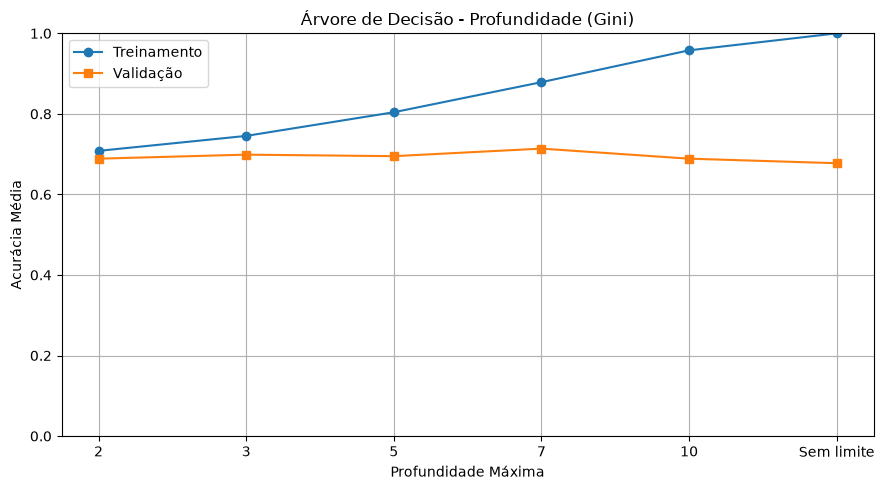

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    tabela_gini["Profundidade"],
    tabela_gini["Acurácia Treino"],
    marker="o",
    label="Treinamento"
)

plt.plot(
    tabela_gini["Profundidade"],
    tabela_gini["Acurácia Validação"],
    marker="s",
    label="Validação"
)

plt.xlabel("Profundidade Máxima")
plt.ylabel("Acurácia Média")
plt.title("Árvore de Decisão - Profundidade (Gini)")

plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(figuras / "09_arvore_gini.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.3. Validação cruzada utilizando Entropia

In [25]:
# Armazena os resultados com Entropia
resultados_entropia = []

for profundidade in profundidades:

    acuracias_treino = []
    acuracias_validacao = []

    for X_tr, X_val, y_tr, y_val in dados_folds:

        # Cria a árvore com Entropia
        arvore = ArvoreDecisaoPyTorch(
            max_depth=profundidade,
            criterio="entropy"
        )

        # Treina o modelo
        arvore.fit(X_tr, y_tr)

        # Realiza previsões
        pred_treino = arvore.predict(X_tr)
        pred_validacao = arvore.predict(X_val)

        # Calcula as acurácias
        acc_treino = (
            (pred_treino == y_tr)
            .float()
            .mean()
            .item()
        )

        acc_validacao = (
            (pred_validacao == y_val)
            .float()
            .mean()
            .item()
        )

        acuracias_treino.append(acc_treino)
        acuracias_validacao.append(acc_validacao)

    # Registra os resultados
    resultados_entropia.append({
        "Profundidade": (
            str(profundidade)
            if profundidade is not None
            else "Sem limite"
        ),
        "Acurácia Treino": np.mean(acuracias_treino),
        "Acurácia Validação": np.mean(acuracias_validacao),
        "Desvio Validação": np.std(
            acuracias_validacao,
            ddof=1
        )
    })

    print(f"Profundidade {profundidade}: concluída!")

print("\nValidação cruzada com Entropia finalizada!")

Profundidade 2: concluída!
Profundidade 3: concluída!
Profundidade 5: concluída!
Profundidade 7: concluída!
Profundidade 10: concluída!
Profundidade None: concluída!

Validação cruzada com Entropia finalizada!


### 4.4. Comparação das acurácias com Entropia

In [26]:
tabela_entropia = pd.DataFrame(resultados_entropia)

# Calcula a diferença entre treino e validação
tabela_entropia["Diferença"] = (
    tabela_entropia["Acurácia Treino"]
    - tabela_entropia["Acurácia Validação"]
)

display(tabela_entropia.round(4))

,Profundidade,Acurácia Treino,Acurácia Validação,Desvio Validação,Diferença
0,2,0.7069,0.6937,0.0140,0.0131
1,3,0.7359,0.6987,0.0394,0.0372
2,5,0.7944,0.7163,0.0524,0.0781
3,7,0.8584,0.7212,0.0338,0.1372
4,10,0.9328,0.7125,0.0449,0.2203
5,Sem limite,1.0000,0.7000,0.0508,0.3000


### 4.5. Evolução das acurácias com Entropia

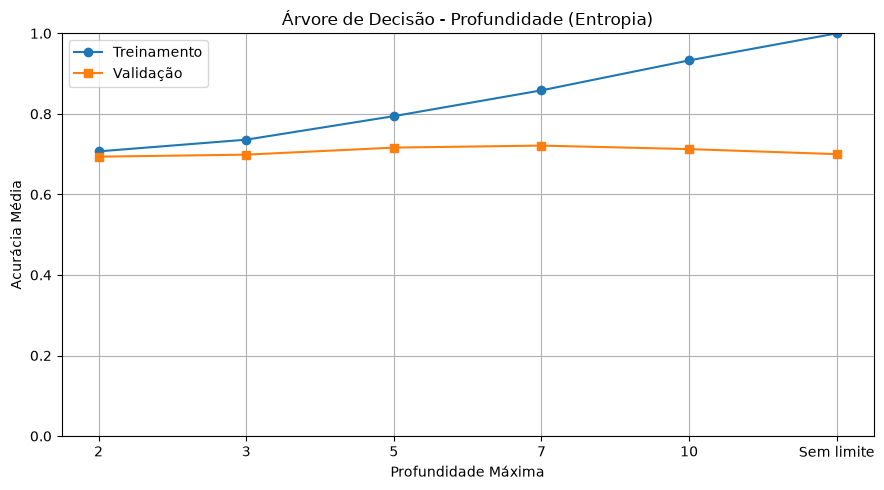

In [27]:
plt.figure(figsize=(9, 5))

# Acurácia de treinamento
plt.plot(
    tabela_entropia["Profundidade"],
    tabela_entropia["Acurácia Treino"],
    marker="o",
    label="Treinamento"
)

# Acurácia de validação
plt.plot(
    tabela_entropia["Profundidade"],
    tabela_entropia["Acurácia Validação"],
    marker="s",
    label="Validação"
)

plt.xlabel("Profundidade Máxima")
plt.ylabel("Acurácia Média")
plt.title("Árvore de Decisão - Profundidade (Entropia)")

plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(figuras / "10_arvore_entropia.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.6. Comparação entre Gini e Entropia

In [28]:
comparacao_criterios = pd.DataFrame({
    "Profundidade": tabela_gini["Profundidade"],
    "Gini": tabela_gini["Acurácia Validação"],
    "Entropia": tabela_entropia["Acurácia Validação"]
})

# Calcula a diferença entre critérios
comparacao_criterios["Diferença"] = (
    comparacao_criterios["Entropia"]
    - comparacao_criterios["Gini"]
)

display(comparacao_criterios.round(4))

,Profundidade,Gini,Entropia,Diferença
0,2,0.6887,0.6937,0.0050
1,3,0.6988,0.6987,-0.0000
2,5,0.6950,0.7163,0.0213
3,7,0.7138,0.7212,0.0075
4,10,0.6887,0.7125,0.0238
5,Sem limite,0.6775,0.7000,0.0225


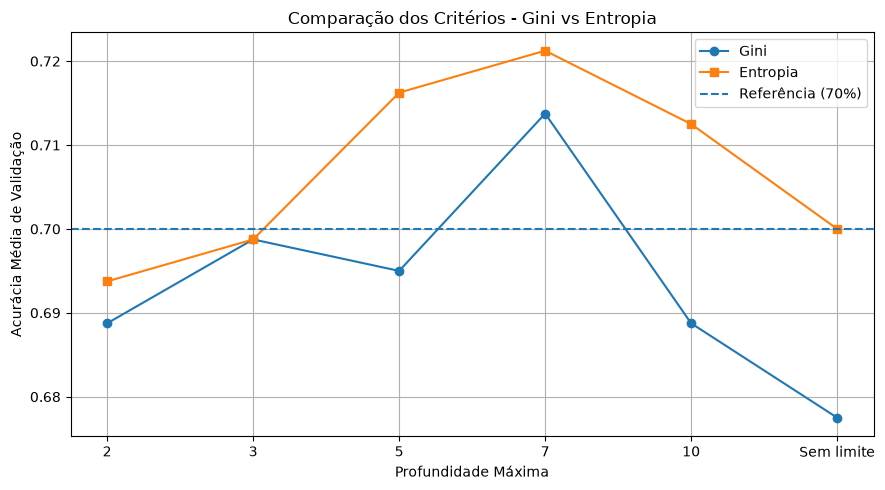

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    comparacao_criterios["Profundidade"],
    comparacao_criterios["Gini"],
    marker="o",
    label="Gini"
)

plt.plot(
    comparacao_criterios["Profundidade"],
    comparacao_criterios["Entropia"],
    marker="s",
    label="Entropia"
)

# Referência: classificador majoritário
plt.axhline(
    y=0.70,
    linestyle="--",
    label="Referência (70%)"
)

plt.xlabel("Profundidade Máxima")
plt.ylabel("Acurácia Média de Validação")
plt.title("Comparação dos Critérios - Gini vs Entropia")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(figuras / "11_comparacao_criterios.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
from pathlib import Path

raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

figuras = raiz / "figuras"
figuras.mkdir(exist_ok=True)

## 5. Interpretação do Modelo

### 5.1. Treinamento da árvore selecionada

In [30]:
melhor_profundidade = 7
melhor_criterio = "entropy"

# Cria a árvore definitiva
arvore_final = ArvoreDecisaoPyTorch(
    max_depth=melhor_profundidade,
    criterio=melhor_criterio
)

# Treina com todas as amostras de treinamento
arvore_final.fit(
    X_treino_tensor,
    y_treino_tensor
)

# Calcula a acurácia de treinamento
previsoes_treino = arvore_final.predict(
    X_treino_tensor
)

acuracia_treino = (
    (previsoes_treino == y_treino_tensor)
    .float()
    .mean()
    .item()
)

print("Critério:", melhor_criterio)
print("Profundidade máxima:", melhor_profundidade)
print(f"Acurácia de treinamento: {acuracia_treino:.4f}")

Critério: entropy
Profundidade máxima: 7
Acurácia de treinamento: 0.8363


### 5.2. Importância dos atributos

In [31]:
importancias = np.zeros(
    X_treino_tensor.shape[1]
)

total_amostras = len(y_treino_tensor)

def calcular_importancias(no):

    # Se for uma folha, não existe divisão
    if no["atributo"] is None:
        return

    # Recupera as informações do nó
    atributo = no["atributo"]
    ganho = no["ganho"]
    amostras = no["amostras"]

    # Contribuição ponderada do atributo
    contribuicao = (
        amostras / total_amostras
    ) * ganho

    importancias[atributo] += contribuicao

    # Percorre os nós filhos
    calcular_importancias(no["esquerda"])
    calcular_importancias(no["direita"])


# Calcula as importâncias da árvore
calcular_importancias(arvore_final.raiz)

# Normaliza para que a soma seja 1
if importancias.sum() > 0:
    importancias = importancias / importancias.sum()

# Cria a tabela
tabela_importancias = pd.DataFrame({
    "Atributo": nomes_atributos,
    "Importância": importancias
})

# Ordena pelos maiores valores
tabela_importancias = tabela_importancias.sort_values(
    by="Importância",
    ascending=False
)

display(tabela_importancias.head(10).round(4))

,Atributo,Importância
3,categoricas__checking_status_no checking,0.1761
55,numericas__credit_amount,0.1461
54,numericas__duration,0.0864
39,categoricas__property_magnitude_real estate,0.0455
5,categoricas__credit_history_critical/other exi...,0.0419
18,categoricas__purpose_used car,0.0365
40,categoricas__other_payment_plans_bank,0.0349
21,categoricas__savings_status_<100,0.0343
56,numericas__installment_commitment,0.0328
24,categoricas__employment_1<=X<4,0.0302


### 5.3. Importância dos atributos originais

In [32]:
# Dicionário com as importâncias originais
importancias_originais = {}

# Agrupa as variáveis categóricas
for variavel in variaveis_categoricas:

    prefixo = f"categoricas__{variavel}_"

    mascara = [
        nome.startswith(prefixo)
        for nome in nomes_atributos
    ]

    importancias_originais[variavel] = (
        importancias[mascara].sum()
    )

# Adiciona as variáveis numéricas
for variavel in variaveis_numericas:

    nome = f"numericas__{variavel}"

    indice = list(nomes_atributos).index(nome)

    importancias_originais[variavel] = (
        importancias[indice]
    )

# Cria a tabela
tabela_originais = pd.DataFrame({
    "Atributo": list(importancias_originais.keys()),
    "Importância": list(importancias_originais.values())
})

tabela_originais = tabela_originais.sort_values(
    by="Importância",
    ascending=False
)

display(tabela_originais.round(4))

print("\nTrês atributos mais importantes:")
display(tabela_originais.head(3))

,Atributo,Importância
0,checking_status,0.2105
14,credit_amount,0.1461
7,property_magnitude,0.0898
2,purpose,0.0871
13,duration,0.0864
3,savings_status,0.0751
4,employment,0.0666
1,credit_history,0.0651
8,other_payment_plans,0.0349
15,installment_commitment,0.0328



Três atributos mais importantes:


,Atributo,Importância
0,checking_status,0.210479
14,credit_amount,0.146117
7,property_magnitude,0.089817


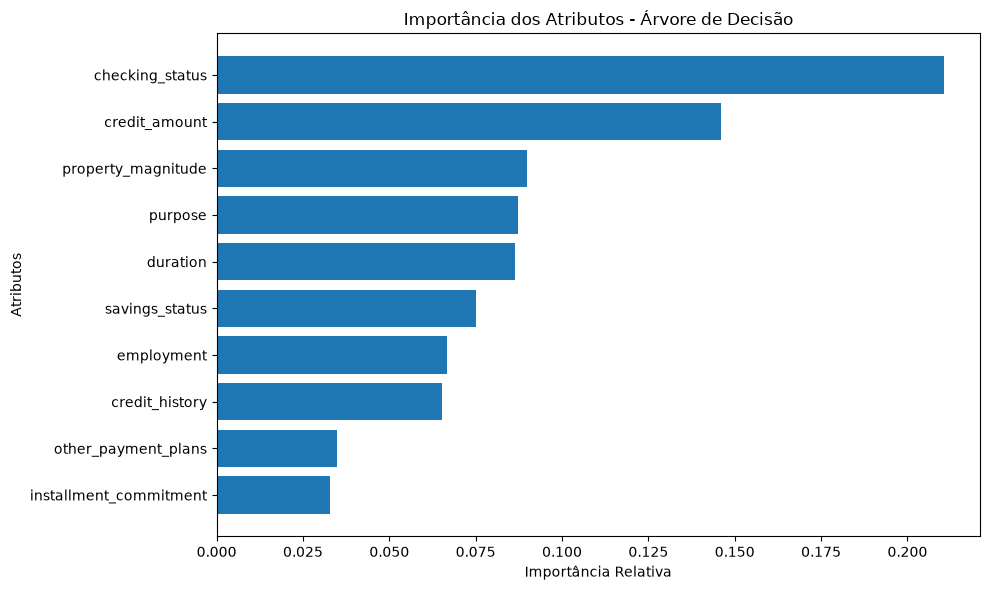

In [33]:
# Seleciona os dez atributos mais importantes
top10 = tabela_originais.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Atributo"][::-1],
    top10["Importância"][::-1]
)

plt.xlabel("Importância Relativa")
plt.ylabel("Atributos")
plt.title("Importância dos Atributos - Árvore de Decisão")

plt.tight_layout()
plt.savefig(figuras / "12_arvore_importancia.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.4. Identificação da folha com maior número de maus pagadores

In [34]:
def encontrar_folha_maus(no, caminho=None):

    if caminho is None:
        caminho = []

    # Verifica se o nó é uma folha
    if no["atributo"] is None:
        return no, caminho

    atributo = no["atributo"]
    limiar = no["limiar"]

    # Caminho pela esquerda
    folha_esq, caminho_esq = encontrar_folha_maus(
        no["esquerda"],
        caminho + [(atributo, "<=", limiar)]
    )

    # Caminho pela direita
    folha_dir, caminho_dir = encontrar_folha_maus(
        no["direita"],
        caminho + [(atributo, ">", limiar)]
    )

    # Compara a quantidade de maus pagadores
    if folha_esq["contagens"][1] >= folha_dir["contagens"][1]:
        return folha_esq, caminho_esq

    return folha_dir, caminho_dir

In [35]:
folha, caminho = encontrar_folha_maus(
    arvore_final.raiz
)

print("Caminho até a folha:\n")

for atributo, operador, limiar in caminho:

    print(
        f"{nomes_atributos[atributo]} "
        f"{operador} {limiar:.4f}"
    )

print("\nInformações da folha:")

print("Total de amostras:", folha["amostras"])
print("Bons pagadores:", folha["contagens"][0])
print("Maus pagadores:", folha["contagens"][1])
print("Classe prevista:", folha["classe"])

Caminho até a folha:

categoricas__checking_status_no checking <= 0.5000
numericas__duration > 11.5000
categoricas__savings_status_<100 > 0.5000
numericas__duration > 15.5000
numericas__credit_amount <= 11141.0000
numericas__duration <= 47.5000
categoricas__purpose_used car <= 0.5000

Informações da folha:
Total de amostras: 143
Bons pagadores: 58
Maus pagadores: 85
Classe prevista: 1


### Interpretação das regras da árvore

O caminho até a folha que concentra o maior número absoluto de clientes de mau risco é composto por condições relacionadas à situação da conta corrente, duração do empréstimo, saldo de poupança, valor solicitado e finalidade do crédito.

De acordo com as regras identificadas, os clientes desse grupo possuem uma categoria de conta corrente diferente de "no checking", poupança inferior a 100 unidades monetárias, empréstimos com duração entre 16 e 47 meses, valores solicitados de até 11.141 unidades monetárias e finalidade diferente da aquisição de veículo usado.

A folha contém 143 clientes, sendo 58 classificados originalmente como bons pagadores e 85 como maus pagadores. Assim, a proporção de mau risco é de aproximadamente 59,44%, fazendo com que o modelo atribua a essa folha a classe 1.

Essas regras representam associações identificadas nos dados de treinamento e não constituem, isoladamente, critérios suficientes para decisões reais de concessão de crédito.

### 5.5. Visualização gráfica da árvore de decisão

In [ ]:
from graphviz import Digraph
from pathlib import Path
import textwrap

# Configura a pasta das figuras
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

figuras = raiz / "figuras"
figuras.mkdir(parents=True, exist_ok=True)

# Cria o gráfico
grafo = Digraph("Arvore_de_Credito")

grafo.attr(
    rankdir="TB",
    nodesep="0.4",
    ranksep="0.7",
    dpi="160"
)

grafo.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="10"
)

# Conta para identificar os nós
contador = [0]

def adicionar_no(no):

    # Cria um identificador único
    id_no = f"no_{contador[0]}"
    contador[0] += 1

    bons, maus = no["contagens"]

    # Verifica se é uma folha
    if no["atributo"] is None:

        classe = no["classe"]

        rotulo = (
            f"Classe: {classe}\n"
            f"Amostras: {no['amostras']}\n"
            f"Bons: {bons} | Maus: {maus}"
        )

        cor = "#D9F2E3" if classe == 0 else "#F8DADA"

    else:

        # Recupera o atributo da divisão
        nome = str(nomes_atributos[no["atributo"]])

        nome = nome.replace("categoricas__", "")
        nome = nome.replace("numericas__", "")

        nome = textwrap.fill(nome, width=28)

        rotulo = (
            f"{nome}\n"
            f"<= {no['limiar']:.2f}\n"
            f"Amostras: {no['amostras']}\n"
            f"Bons: {bons} | Maus: {maus}"
        )

        cor = "#E2ECF7"

    # Adiciona o nó ao gráfico
    grafo.node(
        id_no,
        label=rotulo,
        fillcolor=cor
    )

    # Cria as conexões dos filhos
    if no["atributo"] is not None:

        id_esquerda = adicionar_no(no["esquerda"])
        id_direita = adicionar_no(no["direita"])

        grafo.edge(
            id_no,
            id_esquerda,
            label="Sim"
        )

        grafo.edge(
            id_no,
            id_direita,
            label="Não"
        )

    return id_no


# Constrói o gráfico da árvore definitiva
adicionar_no(arvore_final.raiz)

# Salva uma versão vetorial
arquivo_svg = grafo.render(
    filename=str(figuras / "13_arvore_credito"),
    format="svg",
    cleanup=True
)

# Salva uma versão PNG
arquivo_png = grafo.render(
    filename=str(figuras / "13_arvore_credito"),
    format="png",
    cleanup=True
)

print("Quantidade de nós:", contador[0])
print("SVG salvo em:", arquivo_svg)
print("PNG salvo em:", arquivo_png)

Quantidade de nós: 111
SVG salvo em: c:\Users\peluc\OneDrive\Documentos\UFERSA\SI\github\Sistemas-Inteligentes\figuras\13_arvore_credito.svg
PNG salvo em: c:\Users\peluc\OneDrive\Documentos\UFERSA\SI\github\Sistemas-Inteligentes\figuras\13_arvore_credito.png


### 5.5. Visualização da Árvore de Decisão

![Árvore de Decisão](../figuras/13_arvore_credito.png)

*Figura – Estrutura da árvore de decisão treinada com PyTorch, utilizando Entropia e profundidade máxima 7.*

## 6. Avaliação Final do Modelo

### 6.1. Previsões no conjunto de teste

In [37]:
# Realiza previsões com a árvore definitiva
with torch.no_grad():
    y_pred_tensor = arvore_final.predict(
        X_teste_tensor
    )

# Converte os resultados para NumPy
y_pred = y_pred_tensor.numpy()
y_real = y_teste_tensor.numpy()

# Organiza as previsões
comparacao = pd.DataFrame({
    "Classe Real": y_real,
    "Classe Prevista": y_pred
})

display(comparacao.head(10))

# Distribui as classes previstas
print("\nDistribuição das previsões:")
print(
    pd.Series(y_pred)
    .value_counts()
    .sort_index()
)

,Classe Real,Classe Prevista
0,0,0
1,0,0
2,1,1
3,0,1
4,1,0
5,0,0
6,0,1
7,0,1
8,0,1
9,0,0



Distribuição das previsões:
0    129
1     71
Name: count, dtype: int64


### 6.2. Métricas de classificação

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

acuracia = accuracy_score(y_real, y_pred)

precisao = precision_score(
    y_real, y_pred, zero_division=0
)

recall = recall_score(
    y_real, y_pred, zero_division=0
)

f1 = f1_score(
    y_real, y_pred, zero_division=0
)

print(f"Acurácia: {acuracia:.4f}")
print(f"Precisão: {precisao:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Acurácia: 0.6450
Precisão: 0.4225
Recall:   0.5000
F1-score: 0.4580


In [39]:
relatorio = classification_report(
    y_real,
    y_pred,
    labels=[0, 1],
    target_names=["Bom Risco", "Mau Risco"],
    digits=4,
    zero_division=0
)

print(relatorio)

              precision    recall  f1-score   support

   Bom Risco     0.7674    0.7071    0.7361       140
   Mau Risco     0.4225    0.5000    0.4580        60

    accuracy                         0.6450       200
   macro avg     0.5950    0.6036    0.5970       200
weighted avg     0.6640    0.6450    0.6526       200



### 6.3. Matriz de confusão

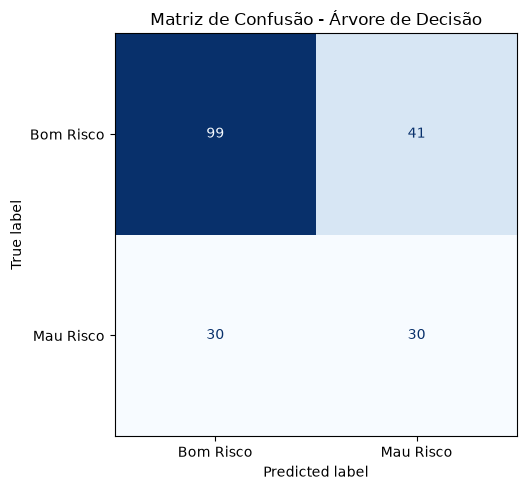

In [40]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

matriz = confusion_matrix(
    y_real,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Bom Risco", "Mau Risco"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Matriz de Confusão - Árvore de Decisão")

plt.tight_layout()

plt.savefig(figuras / "14_arvore_matriz_confusao.png", dpi=300, bbox_inches="tight")

plt.show()

In [41]:
vn, fp, fn, vp = matriz.ravel()

print("Verdadeiros Negativos:", vn)
print("Falsos Positivos:", fp)
print("Falsos Negativos:", fn)
print("Verdadeiros Positivos:", vp)

print("\nAnálise dos erros:")

if fp > fn:
    print("O modelo apresenta mais falsos positivos.")

elif fn > fp:
    print("O modelo apresenta mais falsos negativos.")

else:
    print("Os dois tipos de erro ocorrem igualmente.")

taxa_fn = fn / (fn + vp) if (fn + vp) > 0 else 0

print(f"\nTaxa de falsos negativos: {taxa_fn:.2%}")

Verdadeiros Negativos: 99
Falsos Positivos: 41
Falsos Negativos: 30
Verdadeiros Positivos: 30

Análise dos erros:
O modelo apresenta mais falsos positivos.

Taxa de falsos negativos: 50.00%


### 6.4. Comparação com classificador majoritário

In [42]:
# Classificador que sempre prevê Bom Risco
previsao_referencia = np.zeros_like(y_real)

# Métricas de referência
acc_referencia = accuracy_score(
    y_real, previsao_referencia
)

recall_referencia = recall_score(
    y_real,
    previsao_referencia,
    zero_division=0
)

f1_referencia = f1_score(
    y_real,
    previsao_referencia,
    zero_division=0
)

# Compara os modelos
tabela_comparacao = pd.DataFrame({
    "Modelo": [
        "Árvore de Decisão",
        "Classificador Majoritário"
    ],
    "Acurácia": [
        acuracia,
        acc_referencia
    ],
    "Recall Mau Risco": [
        recall,
        recall_referencia
    ],
    "F1-score Mau Risco": [
        f1,
        f1_referencia
    ]
})

display(tabela_comparacao.round(4))

,Modelo,Acurácia,Recall Mau Risco,F1-score Mau Risco
0,Árvore de Decisão,0.645,0.5,0.458
1,Classificador Majoritário,0.700,0.0,0.000
